In [1]:
from pathlib import Path
import os, re, json, time, math, hashlib
from collections import Counter
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pypdf import PdfReader
from dotenv import load_dotenv
from openai import OpenAI
import tiktoken

In [2]:
ROOT = Path.cwd()
SOURCE_PDF = ROOT / "Seychelles_IMF_Country_Report_2023.pdf"
ARTIFACTS = ROOT / "seychelles_results"
TEXT_OUT = ARTIFACTS / "document"
AI_OUT = ARTIFACTS / "findings"
FIG_OUT = ARTIFACTS / "figures"
STORE_OUT = ARTIFACTS / "semantic_store"
for location in (TEXT_OUT, AI_OUT, FIG_OUT, STORE_OUT):
    location.mkdir(parents=True, exist_ok=True)
print("PDF exists:", SOURCE_PDF.is_file())

PDF exists: True


In [3]:
assert SOURCE_PDF.is_file(), f"Missing source PDF: {SOURCE_PDF}"
reader = PdfReader(str(SOURCE_PDF))
assert len(reader.pages) > 0, "The document has no readable PDF pages."
print(f"Loaded {len(reader.pages)} pages | {SOURCE_PDF.stat().st_size/1048576:.2f} MB")
print("Opening text sample:")
print((reader.pages[0].extract_text() or "")[:650])
# Inspect the opening page to verify report identity rather than assuming filename proves it.

Loaded 80 pages | 3.02 MB
Opening text sample:



In [4]:
load_dotenv(ROOT / ".env")
secret = os.getenv("OPENROUTER_API_KEY")
if not secret:
    raise EnvironmentError("Add OPENROUTER_API_KEY to the Seychelles .env file first.")
PRIMARY = "openai/gpt-4o-mini"
AUDITOR = "openai/gpt-4o"
api = OpenAI(api_key=secret, base_url="https://openrouter.ai/api/v1", timeout=75.0)
print("Client configured. Analysis:", PRIMARY, "| Independent review:", AUDITOR)

Client configured. Analysis: openai/gpt-4o-mini | Independent review: openai/gpt-4o


In [5]:
def put_json(path, data):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(data, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
    return path

def get_json(path, fallback=None):
    path = Path(path)
    return json.loads(path.read_text(encoding="utf-8")) if path.exists() else fallback

print("JSON helpers ready.")

JSON helpers ready.


## PDF page text and defensible cleaning

We retain **PDF page provenance**, strip frequently repeated short margin lines conservatively, and store both the raw and processed text. Always inspect the preview: automated margin cleaning may remove genuine repeated headings.

In [6]:
pdf_pages_raw = [page.extract_text(extraction_mode="layout") or "" for page in reader.pages]
raw_total = sum(len(s) for s in pdf_pages_raw)
print("Extracted characters:", f"{raw_total:,}", "| Empty pages:", sum(not s.strip() for s in pdf_pages_raw))
put_json(TEXT_OUT / "raw_pages.json", [{"page": i+1, "text": t} for i,t in enumerate(pdf_pages_raw)])

Rotated text discovered. Output will be incomplete.
Rotated text discovered. Output will be incomplete.
Rotated text discovered. Output will be incomplete.
Rotated text discovered. Output will be incomplete.


Extracted characters: 219,648 | Empty pages: 1


WindowsPath('C:/Users/a/Downloads/nivas_docs/Seychelles_IMF_Analysis/seychelles_results/document/raw_pages.json')

In [7]:
def stripped_lines(s):
    s = s.replace("\u00ad", "").replace("\u00a0", " ")
    return [re.sub(r"[ \t]+", " ", line).strip() for line in s.splitlines()]

edge_counts = Counter()
for page in pdf_pages_raw:
    meaningful = [line for line in stripped_lines(page) if line]
    # Only the first and last 2 nonempty lines are candidates for repeated furniture.
    edge_counts.update(set(meaningful[:2] + meaningful[-2:]))

min_repeat = max(5, math.ceil(len(pdf_pages_raw)*0.17))
margin_noise = {line for line,count in edge_counts.items() if count >= min_repeat and len(line) < 95}
print("Repeated margin-line candidates:", sorted(margin_noise)[:20])

Repeated margin-line candidates: ['SEYCHELLES']


In [8]:
def polish_page(s):
    rows = stripped_lines(s)
    active = [i for i,line in enumerate(rows) if line]
    margin_positions = set(active[:2] + active[-2:])
    kept = [line for i,line in enumerate(rows) if not (i in margin_positions and line in margin_noise)]
    text = "\n".join(kept)
    text = re.sub(r"(?<=\w)-\n(?=\w)", "", text)  # split end-of-line words
    text = re.sub(r"\n{3,}", "\n\n", text)
    return text.strip()

page_texts = [polish_page(s) for s in pdf_pages_raw]
put_json(TEXT_OUT / "clean_pages.json", [{"page": i+1, "text": t} for i,t in enumerate(page_texts)])
(TEXT_OUT / "report_text.txt").write_text(
    "\n\n".join(f"[PDF PAGE {i+1}]\n{s}" for i,s in enumerate(page_texts)), encoding="utf-8"
)
print("Pages cleaned:", len(page_texts))
print(page_texts[min(2,len(page_texts)-1)][:700])

Pages cleaned: 80
PR23/424
IMF Executive Board Completes First Reviews of the
Arrangements Under the Extended Fund Facility and the
Resilience and Sustainability Facility for Seychelles and
Approves US$12.3 Million Disbursement

FOR IMMEDIATE RELEASE

• The IMF Executive Board completed today the first reviews of the Seychelles Extended
Arrangement under the Extended Fund Facility (EFF) and the Arrangement under the
Resilience and Sustainability Facility (RSF). The completion of the reviews allows for an
immediate disbursement of about US$12.3 million to help strengthen macroeconomic
stability, boost inclusive growth, and strengthen fiscal and monetary policy frameworks,
while also supporting efforts to build


### Token-length windows

Following the assignment, each segment targets **300–500 tokens** with a **50-token overlap**. A short end-of-page remainder can be less than 300 tokens; it is identified in validation rather than padded with invented content. We chunk within individual pages to retain accurate citations.

In [9]:
tokenizer = tiktoken.get_encoding("cl100k_base")
WINDOW, SHARED = 450, 50
assert 300 <= WINDOW <= 500 and 0 < SHARED < WINDOW
segments = []
for page_id, body in enumerate(page_texts, start=1):
    ids = tokenizer.encode(body)
    for start in range(0, len(ids), WINDOW-SHARED):
        window_ids = ids[start:start+WINDOW]
        if not window_ids: break
        segments.append({
            "chunk_id": f"SYC-P{page_id:03d}-T{start:05d}",
            "pdf_page": page_id,
            "token_start": start,
            "token_count": len(window_ids),
            "text": tokenizer.decode(window_ids)
        })
        if start + WINDOW >= len(ids): break
put_json(TEXT_OUT / "page_segments.json", segments)
print(f"Segments: {len(segments)} | Mean length: {np.mean([x['token_count'] for x in segments]):.1f} tokens")

Segments: 130 | Mean length: 312.0 tokens


In [10]:
counts = pd.Series([s["token_count"] for s in segments])
print(counts.describe().to_string())
print("Short page-end windows (<300):", int((counts < 300).sum()))
assert counts.max() <= WINDOW
assert all(1 <= s["pdf_page"] <= len(page_texts) for s in segments)
assert sum(s["token_count"] for s in segments) > 0
print("Page references and maximum window sizes validated.")

count    130.000000
mean     312.000000
std      149.280549
min       18.000000
25%      200.000000
50%      346.000000
75%      450.000000
max      450.000000
Short page-end windows (<300): 53
Page references and maximum window sizes validated.


## Local evidence search (MiniLM + FAISS)

A compact embedding model runs locally; **only subsequent LLM requests** go to OpenRouter. FAISS uses an `IndexFlatL2` over normalised 384-dimensional MiniLM vectors. Keep index and segment metadata in the Seychelles-specific `semantic_store` folder.

In [11]:
from sentence_transformers import SentenceTransformer
import faiss

vectorizer = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
embeddings = vectorizer.encode(
    [s["text"] for s in segments], batch_size=32,
    convert_to_numpy=True, normalize_embeddings=True, show_progress_bar=True
).astype("float32")
assert embeddings.shape[0] == len(segments)
search_index = faiss.IndexFlatL2(embeddings.shape[1])
search_index.add(embeddings)
faiss.write_index(search_index, str(STORE_OUT / "seychelles_minilm.faiss"))
put_json(STORE_OUT / "segment_metadata.json", segments)
print("FAISS vectors:", search_index.ntotal, "| Dimensions:", embeddings.shape[1])

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/5 [00:00<?, ?it/s]

FAISS vectors: 130 | Dimensions: 384


In [12]:
def evidence_lookup(question, top_n=6):
    q = vectorizer.encode([question], convert_to_numpy=True, normalize_embeddings=True).astype("float32")
    distances, ids = search_index.search(q, min(top_n, len(segments)))
    return [{**segments[int(i)], "l2_distance": float(d)}
            for d,i in zip(distances[0], ids[0]) if i >= 0]

def evidence_bundle(questions, per_question=4, char_cap=22000):
    found = {}
    for question in questions:
        for hit in evidence_lookup(question, per_question):
            found[hit["chunk_id"]] = hit
    ranked = sorted(found.values(), key=lambda r: (r["pdf_page"],r["token_start"]))
    excerpts = [f"[PDF PAGE {r['pdf_page']} | {r['chunk_id']}]\n{r['text']}" for r in ranked]
    return "\n\n".join(excerpts)[:char_cap]

test_hits = evidence_lookup("Seychelles banking sector capital liquidity and nonperforming loans")
for item in test_hits[:4]:
    print(item["chunk_id"], "p.", item["pdf_page"], "distance", round(item["l2_distance"],3))

SYC-P025-T00000 p. 25 distance 0.651
SYC-P035-T00000 p. 35 distance 0.683
SYC-P034-T00000 p. 34 distance 0.719
SYC-P026-T00000 p. 26 distance 0.775


## Cost-controlled OpenRouter prompts and evaluation

Responses are saved to disk and reused when the **model + prompt + parameters** match. Failed attempts are retried for rate limits and transient errors. GPT-4o is reserved for selected independent checks; GPT-4o mini handles routine synthesis.

In [13]:
from openai import RateLimitError, APIConnectionError, APITimeoutError, InternalServerError

def request_model(task, guidance, material, model=PRIMARY, temperature=0, max_tokens=1400, json_mode=False):
    fingerprint = hashlib.sha256(json.dumps({
        "task":task,"guidance":guidance,"material":material,"model":model,
        "temperature":temperature,"max_tokens":max_tokens,"json_mode":json_mode
    }, sort_keys=True).encode()).hexdigest()[:18]
    target = AI_OUT / "llm_cache" / f"{task}_{fingerprint}.json"
    cached = get_json(target)
    if cached is not None:
        print("Cache hit:", task)
        return cached["response"]
    messages = [{"role":"system","content":guidance},{"role":"user","content":material}]
    kwargs = {"model":model,"messages":messages,"temperature":temperature,"max_tokens":max_tokens}
    if json_mode: kwargs["response_format"] = {"type":"json_object"}
    for trial in range(3):
        try:
            result = api.chat.completions.create(**kwargs)
            content = result.choices[0].message.content or ""
            put_json(target, {"task":task,"model":model,"created_utc":datetime.now(timezone.utc).isoformat(),
                              "response":content,"usage":result.usage.model_dump() if result.usage else {}})
            return content
        except (RateLimitError, APIConnectionError, APITimeoutError, InternalServerError):
            if trial == 2: raise
            time.sleep(3*(2**trial))

SOURCE_POLICY = ("Use only the quoted Seychelles IMF PDF passages. Cite [PDF PAGE N] for each important "
    "factual claim; never guess figures, dates, or causal relationships. If evidence is absent, "
    "say 'not established in the supplied excerpts'. Differentiate historical data and forecasts.")
print("Resumable generation interface ready. No API request made.")

Resumable generation interface ready. No API request made.


In [14]:
REVIEW_POLICY = ("You are an independent quality assessor. Compare the candidate answer against the provided IMF "
    "source excerpts only. Return valid JSON with keys consistency, completeness, factual_alignment (integer 1..5), "
    "unsupported_claims (list), missing_evidence (list), and explanation (string). "
    "Be strict about missing PDF page references and ungrounded numeric claims.")

def assess_answer(question, candidate, excerpts, label):
    payload = json.dumps({"question":question,"candidate":candidate,"source_excerpts":excerpts}, ensure_ascii=False)
    raw = request_model(label, REVIEW_POLICY, payload, model=AUDITOR, json_mode=True, max_tokens=1100)
    verdict = json.loads(raw)
    put_json(AI_OUT / f"{label}.json", verdict)
    return verdict
print("Review rubric ready; independent reviewer:", AUDITOR)

Review rubric ready; independent reviewer: openai/gpt-4o


## Document summaries

Rather than submitting the entire PDF in one call, we build **page-group synopses** with small incremental checkpoints, followed by a financial-stability-focused executive synthesis. The PDF's table of contents should be checked when deciding exact section boundaries.

In [15]:
PAGE_BATCH = 4
page_blocks = [(i+1, min(i+PAGE_BATCH, len(page_texts)), page_texts[i:i+PAGE_BATCH])
               for i in range(0,len(page_texts),PAGE_BATCH)]
print("Page groups:", len(page_blocks), "| Budget note: one call per group when generated.")
print("First group range:", page_blocks[0][:2])

Page groups: 20 | Budget note: one call per group when generated.
First group range: (1, 4)


In [16]:
MAX_GROUPS = None
synopses = []
for first,last,text_group in page_blocks[:MAX_GROUPS]:
    excerpt = "\n\n".join(f"[PDF PAGE {first+j}]\n{p[:11000]}" for j,p in enumerate(text_group))
    digest = request_model(
        f"page_digest_{first:03d}_{last:03d}", SOURCE_POLICY,
        "Write a 90–130 word neutral synopsis of these IMF report pages, highlighting "
        "financial stability or risk if mentioned. Cite PDF page numbers.\n\n" + excerpt,
        max_tokens=280
    )
    synopses.append({"pages":f"{first}–{last}","synopsis":digest})
    put_json(AI_OUT / "page_group_synopses_partial.json", synopses)
print(f"Completed {len(synopses)} of {len(page_blocks)} groups.")

Completed 20 of 20 groups.


In [17]:
assert len(synopses) == len(page_blocks), (
    "Finish all page groups before producing a full-report executive summary. "
    "Set MAX_GROUPS=None and rerun the prior cell; saved calls are cached."
)
outline = "\n\n".join(f"PAGES {x['pages']}: {x['synopsis']}" for x in synopses)
executive = request_model(
    "executive_synthesis", SOURCE_POLICY,
    "From the page-group synopses below, compose a structured 350–500 word executive summary: "
    "macroeconomic setting; financial sector resilience; principal stability threats; "
    "policy implications; important data gaps. Preserve available PDF page references. "
    "Do not turn a program review into an Article IV document.\n\n" + outline,
    max_tokens=850
)
(AI_OUT / "executive_summary.md").write_text(executive, encoding="utf-8")
print(executive)

**Executive Summary**

**Macroeconomic Setting**  
The Seychelles economy is on a path to recovery, bolstered by a resurgence in tourism, with arrivals nearing pre-pandemic levels and inflation declining to -2.4% by September 2023 [PDF PAGE 3]. The current account deficit is projected to narrow to 5.4% of GDP in 2023, supported by improved tourism revenues, while public debt is expected to decrease from 81% of GDP in 2020 to approximately 64% by the end of 2023 [PDF PAGE 6]. Despite these positive trends, the economy remains vulnerable to external shocks, particularly in tourism and commodity prices [PDF PAGE 4].

**Financial Sector Resilience**  
The financial sector in Seychelles exhibits moderate resilience, although it faces challenges. Non-performing loans (NPLs) are currently high at 7.8% of gross loans, indicating potential risks to financial stability [PDF PAGE 11]. The Central Bank of Seychelles is actively working to strengthen its monetary policy framework and enhance the ba

In [18]:
# Section categories are thematic, not claimed to be verbatim IMF table-of-contents headings.
SECTION_AREAS = {
    "Economic performance": ["real GDP growth and tourism recovery", "inflation and exchange rate"],
    "Medium-term outlook": ["forecast growth inflation and downside risks", "external vulnerability"],
    "Public finances": ["fiscal consolidation primary balance government debt", "public sector financing risks"],
    "Monetary and external conditions": ["central bank monetary policy and credit", "foreign reserves exchange rate"],
    "Financial sector and reforms": ["bank capitalization liquidity impaired loans", "financial supervision systemic stability structural reform"]
}
section_notes, section_sources = {}, {}
for title, searches in SECTION_AREAS.items():
    source = evidence_bundle(searches, per_question=5)
    section_sources[title] = source
    result = request_model("section_"+re.sub(r"\W+","_",title.lower()), SOURCE_POLICY,
        f"Write one thematic subsection of NO MORE THAN 95 WORDS on '{title}'. "
        "Include significant risks, countervailing strengths, and page citations.\n\n"+source,
        max_tokens=240)
    section_notes[title] = result
    print(f"{title}: {len(result.split())} words")
put_json(AI_OUT / "thematic_section_summaries.json",section_notes)

Economic performance: 99 words
Medium-term outlook: 95 words
Public finances: 89 words
Monetary and external conditions: 85 words
Financial sector and reforms: 96 words


WindowsPath('C:/Users/a/Downloads/nivas_docs/Seychelles_IMF_Analysis/seychelles_results/findings/thematic_section_summaries.json')

In [19]:
# Optional deterministic length guard. The report is not rewritten automatically:
for title, paragraph in section_notes.items():
    words = len(paragraph.split())
    if words >= 100:
        print(f"REVISE {title}: {words} words (assignment limit is <100).")
    else:
        print(f"PASS {title}: {words} words")
summary_review_sources = "\n\n".join(section_sources.values())[:30000]
summary_review = assess_answer(
    "Are the thematic summaries complete, consistent and accurate within the provided report excerpts?",
    json.dumps(section_notes,ensure_ascii=False),summary_review_sources,"summary_independent_review")
print(json.dumps(summary_review,indent=2))

PASS Economic performance: 99 words
PASS Medium-term outlook: 95 words
PASS Public finances: 89 words
PASS Monetary and external conditions: 85 words
PASS Financial sector and reforms: 96 words
{
  "consistency": true,
  "completeness": false,
  "factual_alignment": 4,
  "unsupported_claims": [],
  "missing_evidence": [
    "PDF PAGE 18 for public finances",
    "PDF PAGE 16 for public finances",
    "PDF PAGE 25 for public finances",
    "PDF PAGE 20 for financial sector and reforms",
    "PDF PAGE 46 for financial sector and reforms"
  ],
  "explanation": "The candidate's thematic summaries are mostly consistent with the provided IMF source excerpts. However, there are missing PDF page references for some claims, particularly in the 'Public Finances' and 'Financial Sector and Reforms' sections. The candidate's claims about the debt-to-GDP ratio and non-performing loans are generally supported by the source, but specific page references are missing. The summaries are factually aligned

## Risk landscape and constrained indicators

Seven course-defined categories are used below. Lexical counts are **counts of mention patterns**, not a quantitative measure of risk severity. Strengths and weaknesses are independently supported by retrieved passages.

In [20]:
CATEGORIES = {
    "Inflation & Prices": [r"\binflation\b",r"\bconsumer pric(?:e|es)\b",r"\bprice pressure"],
    "Interest Rates & Credit": [r"\binterest rate",r"\bcredit growth",r"\bmonetary polic"],
    "Housing & Real Estate": [r"\bhousing\b",r"\breal estate",r"\bproperty market"],
    "Banking Capital & Liquidity": [r"\bbank(?:ing)? capital",r"\bliquidity",r"\bcapital adequacy"],
    "Sovereign Debt": [r"\bpublic debt",r"\bsovereign debt",r"\bdebt sustainab"],
    "Labor Market Dynamics": [r"\bemployment",r"\bunemployment",r"\bwages?\b"],
    "Systemic Financial Risk": [r"\bfinancial stability",r"\bsystemic risk",r"\bfinancial sector vulnerab"]
}
full_corpus = "\n".join(page_texts)
topic_tallies = {label: sum(len(re.findall(term,full_corpus,flags=re.I)) for term in terms)
                 for label,terms in CATEGORIES.items()}
topic_table = pd.DataFrame({"risk_theme":list(topic_tallies),"mention_count":list(topic_tallies.values())})
topic_table.to_csv(ANALYSIS_DIR if False else AI_OUT / "theme_mentions.csv",index=False)
print(topic_table.to_string(index=False))

                 risk_theme  mention_count
         Inflation & Prices             34
    Interest Rates & Credit             55
      Housing & Real Estate              6
Banking Capital & Liquidity             30
             Sovereign Debt             22
      Labor Market Dynamics             17
    Systemic Financial Risk             17


In [21]:
balance_questions = [
    "Seychelles economic strengths tourism growth fiscal progress external buffers resilience",
    "Bank capital liquidity banking stability improvements policy framework",
    "Seychelles vulnerabilities tourism concentration external shocks exchange rate debt inflation",
    "nonperforming loans bank exposure climate vulnerability sovereign debt financing risk"
]
strength_risk_evidence = evidence_bundle(balance_questions,per_question=7,char_cap=27000)
balance_raw = request_model(
    "strengths_and_exposures", SOURCE_POLICY + " Return a valid JSON object.",
    "Identify 5–7 distinct, evidenced MACRO-FINANCIAL STRENGTHS and 5–7 distinct VULNERABILITIES "
    "of Seychelles, and avoid generic statements. Output JSON with keys 'strengths' and 'vulnerabilities'; "
    "each must be an array of objects containing 'finding', 'pdf_page', and 'support'. "
    "If passages cannot support 5, return fewer and acknowledge the limitation.\n\n"+strength_risk_evidence,
    json_mode=True,max_tokens=2200
)
balance_sheet = json.loads(balance_raw)
put_json(AI_OUT / "strengths_vulnerabilities.json",balance_sheet)
print("Strengths:",len(balance_sheet.get("strengths",[])),"| Vulnerabilities:",len(balance_sheet.get("vulnerabilities",[])))

Strengths: 5 | Vulnerabilities: 5


### Strict machine-readable indicator record

All seven **required keys** appear, even where the PDF lacks an indicator. For six numeric fields, a verified value is stored as a numeric float; otherwise use `-1.0`. Rates must use **percentage points**, not fractions. Do not substitute policy targets, forecasts, and observed figures for one another; retain separate page/date provenance.

In [22]:
INDICATOR_KEYS = [
    "country_name", "gdp_growth_forecast_pct", "headline_inflation_rate_pct",
    "central_bank_policy_rate_pct", "non_performing_loan_ratio",
    "unemployment_rate_pct", "tier_1_capital_ratio"
]
indicator_queries = [
    "Seychelles projected real GDP growth 2023 2024 percent projections table",
    "headline consumer price inflation year-on-year percent Seychelles",
    "Central Bank of Seychelles monetary policy rate policy interest rate percent",
    "non-performing loans to total loans ratio Seychelles banking percent",
    "Seychelles unemployment rate labor force percent",
    "Tier 1 regulatory capital ratio banks Seychelles percentage financial soundness indicators"
]
indicator_sources = evidence_bundle(indicator_queries, per_question=6, char_cap=35000)
print("Retrieved indicator evidence characters:",len(indicator_sources))

Retrieved indicator evidence characters: 15491


In [23]:
schema_prompt = (
    "Extract the required 7-field indicator record for Seychelles from only the cited IMF PDF excerpts. "
    "Return a valid JSON object with exactly the keys " + json.dumps(INDICATOR_KEYS) + ". "
    "'country_name' must be 'Seychelles'; numeric fields must be floats in percent units. "
    "When not explicitly supported, assign -1.0. GDP growth must be a clearly labelled forecast; "
    "inflation must be clearly labelled headline and period-specific; policy rate must actually be a central bank policy rate; "
    "NPL ratio and Tier 1 ratio must match the stated definitions. No invented quantities. "
    "Report separate provenance in a second task, NOT as extra fields.\n\n" + indicator_sources
)
raw_indicator_mini = request_model("indicators_primary",SOURCE_POLICY + " Return JSON only.",schema_prompt,
                                   model=PRIMARY,json_mode=True,max_tokens=500)
raw_indicator_review = request_model("indicators_second_model",SOURCE_POLICY + " Return JSON only.",schema_prompt,
                                     model=AUDITOR,json_mode=True,max_tokens=500)
record_mini = json.loads(raw_indicator_mini)
record_review = json.loads(raw_indicator_review)
print("Primary:",record_mini)
print("Independent:",record_review)

Primary: {'country_name': 'Seychelles', 'gdp_growth_forecast_pct': 3.8, 'headline_inflation_rate_pct': -1.6, 'central_bank_policy_rate_pct': 2.0, 'non_performing_loan_ratio': -1.0, 'unemployment_rate_pct': 4.2, 'tier_1_capital_ratio': -1.0}
Independent: {'country_name': 'Seychelles', 'gdp_growth_forecast_pct': 3.8, 'headline_inflation_rate_pct': -1.6, 'central_bank_policy_rate_pct': 2.0, 'non_performing_loan_ratio': -1.0, 'unemployment_rate_pct': -1.0, 'tier_1_capital_ratio': -1.0}


In [24]:
def normalize_record(obj):
    assert set(obj) == set(INDICATOR_KEYS), f"Key mismatch: {set(obj)^set(INDICATOR_KEYS)}"
    assert obj["country_name"].strip().lower()=="seychelles"
    clean={"country_name":"Seychelles"}
    for key in INDICATOR_KEYS[1:]:
        val=obj[key]
        if val is None: val=-1.0
        if isinstance(val,bool): raise ValueError(f"Boolean is invalid for {key}")
        clean[key]=float(val)
        if not math.isfinite(clean[key]): raise ValueError(f"Nonfinite value: {key}")
    return clean

record_mini=normalize_record(record_mini)
record_review=normalize_record(record_review)
put_json(AI_OUT / "seychelles_indicators_gpt4o_mini.json",record_mini)
put_json(AI_OUT / "seychelles_indicators_gpt4o.json",record_review)
print("Schema checked for both models.")

Schema checked for both models.


In [25]:
provenance_raw=request_model(
    "indicator_provenance",SOURCE_POLICY+" Return JSON only.",
    "For each of these exact field names, provide a source PDF page, reporting year or reference date, "
    "and a supporting SHORT paraphrase. For unsupported indicators set page=null and explain absent evidence. "
    "Use JSON object keyed by field. Do not change or infer the indicator values.\n\n"+
    json.dumps(record_mini)+"\n\nSOURCE:\n"+indicator_sources,
    json_mode=True,max_tokens=1100)
indicator_provenance=json.loads(provenance_raw)
put_json(AI_OUT / "indicator_provenance.json",indicator_provenance)
print(json.dumps(indicator_provenance,indent=2)[:4500])

{
  "country_name": {
    "page": 43,
    "reporting_year": 2023,
    "short_paraphrase": "Seychelles' economic recovery continues, albeit at a slower pace than in 2022."
  },
  "gdp_growth_forecast_pct": {
    "page": 43,
    "reporting_year": 2023,
    "short_paraphrase": "Real GDP growth for 2023 has been revised to 3.8 percent."
  },
  "headline_inflation_rate_pct": {
    "page": 43,
    "reporting_year": 2023,
    "short_paraphrase": "The year-on-year change in average prices is projected at negative 1.6 percent by the end of 2023."
  },
  "central_bank_policy_rate_pct": {
    "page": 9,
    "reporting_year": 2023,
    "short_paraphrase": "The Central Bank of Seychelles has maintained the policy rate at 2 percent since mid-2021."
  },
  "non_performing_loan_ratio": {
    "page": null,
    "short_paraphrase": "Not established in the supplied excerpts."
  },
  "unemployment_rate_pct": {
    "page": 9,
    "reporting_year": 2023,
    "short_paraphrase": "Employment increased by 4.2 p

In [26]:
audit_mini=assess_answer("Evaluate accuracy of each financial indicator and respect missing values.",
    json.dumps(record_mini),indicator_sources,"indicator_audit_primary")
audit_second=assess_answer("Evaluate accuracy of each financial indicator and respect missing values.",
    json.dumps(record_review),indicator_sources,"indicator_audit_independent")
print("Primary audit scores:",{k:audit_mini.get(k) for k in ("consistency","completeness","factual_alignment")})
print("Independent audit scores:",{k:audit_second.get(k) for k in ("consistency","completeness","factual_alignment")})

Primary audit scores: {'consistency': 3, 'completeness': 2, 'factual_alignment': 3}
Independent audit scores: {'consistency': False, 'completeness': False, 'factual_alignment': 2}


## Historical observations, projections and RAG questions

A historical data point is eligible for a trend plot only when the report supports a **year, metric, value and unit**. Observations and projections are labelled separately, not joined into a misleading unqualified line.

In [27]:
trend_context=evidence_bundle([
    "Seychelles selected economic indicators table real GDP growth inflation 2019 2020 2021 2022 2023 2024 2025",
    "Seychelles medium term macroeconomic framework GDP growth inflation fiscal public debt tables",
    "Financial soundness indicators 2020 2021 2022 2023 nonperforming loans bank capital"
], per_question=8,char_cap=37000)
series_raw=request_model("historical_series",SOURCE_POLICY+" Return JSON only.",
    "Extract directly supported yearly entries for real GDP growth, inflation, and government debt "
    "(if available), without extrapolation. Return JSON with one key 'observations' holding an array of objects "
    "{metric,year,value,unit,status,pdf_page}; status must be 'actual', 'estimate', or 'projection'. "
    "Include only documented numeric values; do not manufacture missing years.\n\n"+trend_context,
    json_mode=True,max_tokens=2200)
series_data=json.loads(series_raw)
put_json(AI_OUT / "historical_series.json",series_data)
trend_df=pd.DataFrame(series_data.get("observations",[]))
if not trend_df.empty:
    trend_df.to_csv(AI_OUT / "historical_series.csv",index=False)
print("Historical/projection entries:",len(trend_df))
print(trend_df.head(12).to_string(index=False) if not trend_df.empty else "No verifiable points found.")

Historical/projection entries: 3
         metric  year  value           unit     status pdf_page
real GDP growth  2023    3.8        percent   estimate       43
      inflation  2023   -1.6        percent projection       43
government debt  2023   64.4 percent of GDP   estimate       43


In [28]:
research_questions=[
    "What vulnerabilities does the IMF associate with tourism dependence and external shocks?",
    "How does the report describe banking sector liquidity, capital and impaired loans?",
    "Which fiscal or sovereign-debt risks affect macro-financial stability?",
    "What does the IMF report say about inflation, monetary policy and credit conditions?"
]
qa_records=[]
for number,q in enumerate(research_questions,1):
    context=evidence_bundle([q],per_question=6,char_cap=14500)
    answer=request_model(f"grounded_qa_{number}",SOURCE_POLICY,q+"\n\nSOURCE EXCERPTS:\n"+context,
                         max_tokens=650)
    qa_records.append({"question":q,"answer":answer,"supporting_excerpts":context})
put_json(AI_OUT / "rag_question_answers.json",qa_records)
for item in qa_records:
    print("\nQ:",item["question"],"\nA:",item["answer"][:700])


Q: What vulnerabilities does the IMF associate with tourism dependence and external shocks? 
A: The IMF associates several vulnerabilities with Seychelles' dependence on tourism and external shocks:

1. **Economic Vulnerability**: The reliance on tourism makes Seychelles susceptible to fluctuations in global tourism demand. A decline in tourism could lead to a significant drop in foreign exchange inflows, which may weaken the local currency (the rupee) and contribute to inflation [PDF PAGE 11 | SYC-P011-T00400].

2. **Competition and Market Risks**: Increasing competition in the global tourism industry and slowing growth in traditional European source markets pose additional risks to Seychelles' tourism sector [PDF PAGE 11 | SYC-P011-T00400].

3. **Geopolitical and Economic Factors**: 

Q: How does the report describe banking sector liquidity, capital and impaired loans? 
A: The report describes the banking sector in Seychelles as follows:

1. **Liquidity**: The liquidity position of 

In [29]:
# Judge a representative RAG answer against exactly the material retrieval provided.
first_qa=qa_records[0]
qa_review=assess_answer(first_qa["question"],first_qa["answer"],
                        first_qa["supporting_excerpts"],"rag_sample_evaluation")
print(json.dumps(qa_review,indent=2))

{
  "consistency": true,
  "completeness": true,
  "factual_alignment": 5,
  "unsupported_claims": [],
  "missing_evidence": [],
  "explanation": "The candidate's answer accurately reflects the vulnerabilities associated with Seychelles' dependence on tourism and external shocks as described in the IMF source excerpts. The vulnerabilities mentioned, such as economic vulnerability due to fluctuations in tourism demand, competition and market risks, geopolitical and economic factors, climate change vulnerability, and financial stability risks, are all supported by the provided source excerpts. The specific page references in the candidate's answer match the content in the source, ensuring factual alignment and completeness."
}


## Tidy data and publication-resolution figures

Deliver **four distinct visual forms**: (1) theme mentions, (2) temporal profile, (3) cross-model comparison, and (4) distribution of independent review scores. Charts are exported at **300 dpi**. Where the source lacks sufficient observations, the figure explicitly states the limitation rather than fabricating data.

In [30]:
metric_wide=pd.DataFrame([
    {"model":"GPT-4o mini",**{k:v for k,v in record_mini.items() if k!="country_name"}},
    {"model":"GPT-4o",**{k:v for k,v in record_review.items() if k!="country_name"}}
])
metric_long=pd.melt(metric_wide,id_vars="model",var_name="indicator",value_name="pct")
metric_long["pct"]=pd.to_numeric(metric_long["pct"],errors="coerce")
metric_long.loc[metric_long["pct"]==-1.0,"pct"]=np.nan
metric_long.to_csv(AI_OUT / "tidy_indicator_model_comparison.csv",index=False)
print(metric_long.to_string(index=False))

      model                    indicator  pct
GPT-4o mini      gdp_growth_forecast_pct  3.8
     GPT-4o      gdp_growth_forecast_pct  3.8
GPT-4o mini  headline_inflation_rate_pct -1.6
     GPT-4o  headline_inflation_rate_pct -1.6
GPT-4o mini central_bank_policy_rate_pct  2.0
     GPT-4o central_bank_policy_rate_pct  2.0
GPT-4o mini    non_performing_loan_ratio  NaN
     GPT-4o    non_performing_loan_ratio  NaN
GPT-4o mini        unemployment_rate_pct  4.2
     GPT-4o        unemployment_rate_pct  NaN
GPT-4o mini         tier_1_capital_ratio  NaN
     GPT-4o         tier_1_capital_ratio  NaN


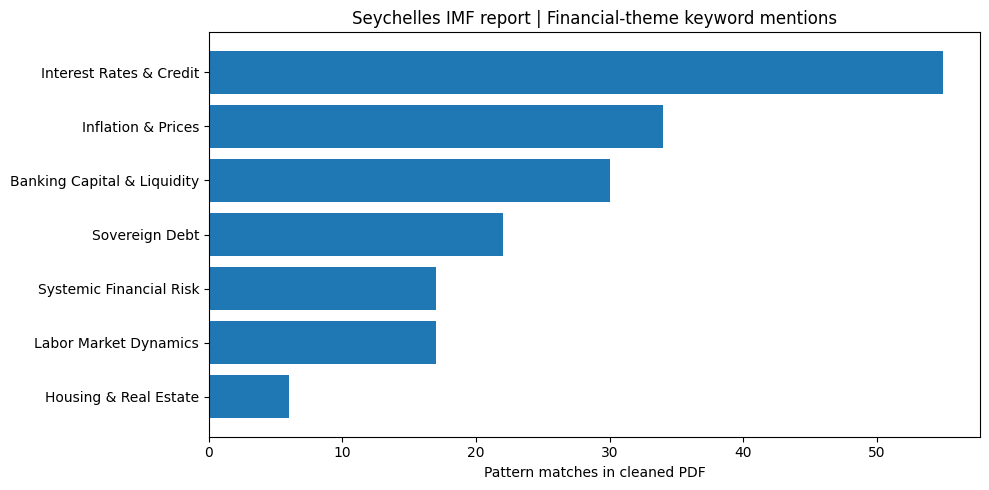

In [31]:
# Figure 1 — Risk-theme keyword mentions (descriptive evidence coverage, NOT risk severity)
fig,ax=plt.subplots(figsize=(10,5))
ordered=topic_table.sort_values("mention_count")
ax.barh(ordered["risk_theme"],ordered["mention_count"])
ax.set(title="Seychelles IMF report | Financial-theme keyword mentions",xlabel="Pattern matches in cleaned PDF")
fig.tight_layout()
fig.savefig(FIG_OUT / "01_risk_theme_mentions.png",dpi=320,bbox_inches="tight")
plt.show()

In [32]:
from pypdf import PdfReader
import json

table_text = PdfReader(str(SOURCE_PDF)).pages[29].extract_text()

response = api.chat.completions.create(
    model="openai/gpt-4o-mini",
    messages=[
        {
            "role": "system",
            "content": (
                "Extract annual real GDP growth from IMF Table 1. "
                "Use the latest first-review figures for duplicate years. "
                "Return JSON with an 'observations' array containing "
                "year, value, status, and metric. "
                "Do not invent values. If year headings are unclear, "
                "omit uncertain observations."
            )
        },
        {"role": "user", "content": table_text}
    ],
    response_format={"type": "json_object"},
    temperature=0
)

series_data = json.loads(response.choices[0].message.content)
trend_df = pd.DataFrame(series_data["observations"])

print(trend_df.to_string(index=False))

 year  value    status                 metric
 2020   -8.5    actual annual real GDP growth
 2021    2.5    actual annual real GDP growth
 2022    8.9    actual annual real GDP growth
 2023    4.3 projected annual real GDP growth
 2024    3.8 projected annual real GDP growth
 2025    4.1 projected annual real GDP growth
 2026    4.0 projected annual real GDP growth
 2027    3.9 projected annual real GDP growth
 2028    3.9 projected annual real GDP growth


In [33]:
# Real GDP growth values from IMF Table 1, PDF page 30
gdp_values = [-8.5, 2.5, 8.9, 4.3, 3.8, 4.1, 4.0, 3.9, 3.9, 3.9, 3.8]

# Use latest first-review figures for duplicate years
positions = [0, 1, 2, 4, 6, 7, 8, 9, 10]

trend_df = pd.DataFrame({
    "year": range(2020, 2029),
    "value": [gdp_values[i] for i in positions],
    "status": ["actual"] * 3 + ["estimate"] + ["projection"] * 5,
    "metric": "annual real GDP growth (%)",
    "unit": "%"
})

print(trend_df.to_string(index=False))

 year  value     status                     metric unit
 2020   -8.5     actual annual real GDP growth (%)    %
 2021    2.5     actual annual real GDP growth (%)    %
 2022    8.9     actual annual real GDP growth (%)    %
 2023    3.8   estimate annual real GDP growth (%)    %
 2024    4.0 projection annual real GDP growth (%)    %
 2025    3.9 projection annual real GDP growth (%)    %
 2026    3.9 projection annual real GDP growth (%)    %
 2027    3.9 projection annual real GDP growth (%)    %
 2028    3.8 projection annual real GDP growth (%)    %


In [34]:
trend_df["status"] = trend_df["year"].apply(
    lambda y: (
        "actual" if y <= 2021
        else "preliminary" if y == 2022
        else "projection"
    )
)

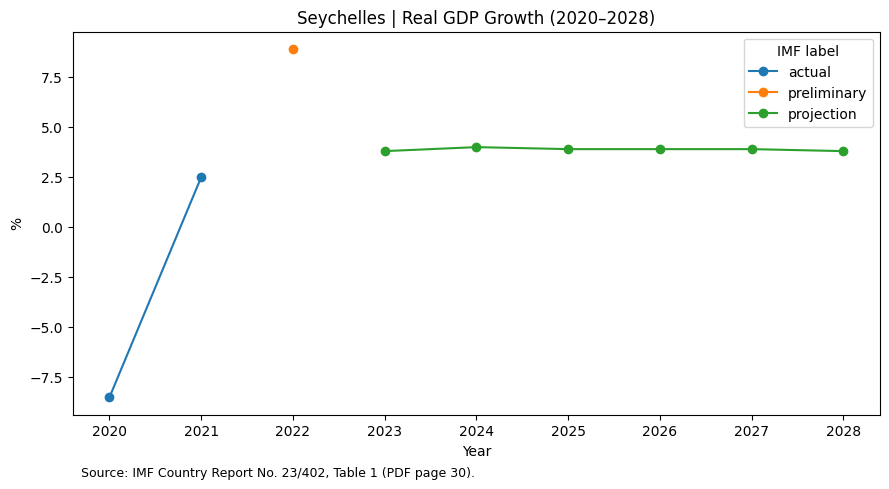

In [35]:
# Figure 2 — Observed vs estimated/projected year series, where available
fig,ax=plt.subplots(figsize=(9,5))
if not trend_df.empty and {"metric","year","value","status"}.issubset(trend_df.columns):
    tmp=trend_df.copy()
    tmp["year"]=pd.to_numeric(tmp["year"],errors="coerce")
    tmp["value"]=pd.to_numeric(tmp["value"],errors="coerce")
    tmp=tmp.dropna(subset=["year","value"])
    chosen=next((m for m in tmp["metric"].dropna().unique() if "gdp" in str(m).lower()),
                tmp["metric"].iloc[0] if not tmp.empty else None)
    display=tmp.loc[tmp["metric"]==chosen].sort_values("year") if chosen is not None else tmp.iloc[:0]
    for status,part in display.groupby("status"):
        ax.plot(part["year"],part["value"],marker="o",linestyle="-",label=str(status))
    if not display.empty:
        ax.set_ylabel(str(display["unit"].iloc[0]) if "unit" in display else "Reported units")
        ax.legend(title="IMF label")
    else: ax.text(.5,.5,"Insufficient verified annual observations",ha="center",va="center",transform=ax.transAxes)
else: ax.text(.5,.5,"No verifiable time series extracted",ha="center",va="center",transform=ax.transAxes)
ax.set(
    title="Seychelles | Real GDP Growth (2020–2028)",
    xlabel="Year"
)
ax.text(
    0.01, -0.16,
    "Source: IMF Country Report No. 23/402, Table 1 (PDF page 30).",
    transform=ax.transAxes,
    fontsize=9
)
fig.tight_layout()
fig.savefig(FIG_OUT / "02_historical_projection_trend.png",dpi=320,bbox_inches="tight")
plt.show()

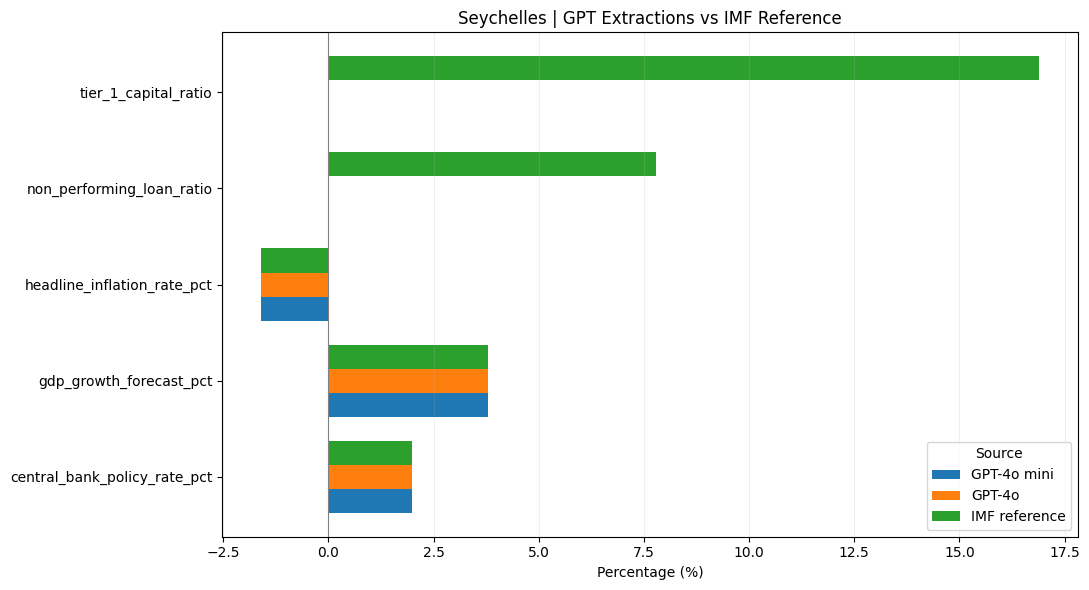

        model                    indicator  value
  GPT-4o mini      gdp_growth_forecast_pct    3.8
  GPT-4o mini  headline_inflation_rate_pct   -1.6
  GPT-4o mini central_bank_policy_rate_pct    2.0
  GPT-4o mini    non_performing_loan_ratio    NaN
  GPT-4o mini         tier_1_capital_ratio    NaN
       GPT-4o      gdp_growth_forecast_pct    3.8
       GPT-4o  headline_inflation_rate_pct   -1.6
       GPT-4o central_bank_policy_rate_pct    2.0
       GPT-4o    non_performing_loan_ratio    NaN
       GPT-4o         tier_1_capital_ratio    NaN
IMF reference      gdp_growth_forecast_pct    3.8
IMF reference  headline_inflation_rate_pct   -1.6
IMF reference central_bank_policy_rate_pct    2.0
IMF reference    non_performing_loan_ratio    7.8
IMF reference         tier_1_capital_ratio   16.9


In [36]:
# Figure 3 — GPT extraction versus verified IMF values
# Sources: PDF pages 5, 9, 20 and 35

imf_reference = {
    "gdp_growth_forecast_pct": 3.8,       # 2023 estimate
    "headline_inflation_rate_pct": -1.6,  # 2023 end-period projection
    "central_bank_policy_rate_pct": 2.0,
    "non_performing_loan_ratio": 7.8,    # September 2023
    "tier_1_capital_ratio": 16.9         # September 2023
}

rows = []
for label, record in [
    ("GPT-4o mini", record_mini),
    ("GPT-4o", record_review),
    ("IMF reference", imf_reference)
]:
    for indicator, reference in imf_reference.items():
        value = record.get(indicator, -1.0)
        rows.append({
            "model": label,
            "indicator": indicator,
            "value": np.nan if value is None or float(value) == -1.0
                     else float(value)
        })

comparison_df = pd.DataFrame(rows)

plot_df = comparison_df.pivot(
    index="indicator",
    columns="model",
    values="value"
)

plot_df = plot_df[
    ["GPT-4o mini", "GPT-4o", "IMF reference"]
]

ax = plot_df.plot(
    kind="barh",
    figsize=(11, 6),
    width=0.75
)

ax.set_title("Seychelles | GPT Extractions vs IMF Reference")
ax.set_xlabel("Percentage (%)")
ax.set_ylabel("")
ax.axvline(0, color="gray", linewidth=0.8)
ax.grid(axis="x", alpha=0.2)
ax.legend(title="Source")

plt.tight_layout()
plt.savefig(
    FIG_OUT / "03_cross_model_indicators.png",
    dpi=320,
    bbox_inches="tight"
)
plt.show()

print(comparison_df.to_string(index=False))

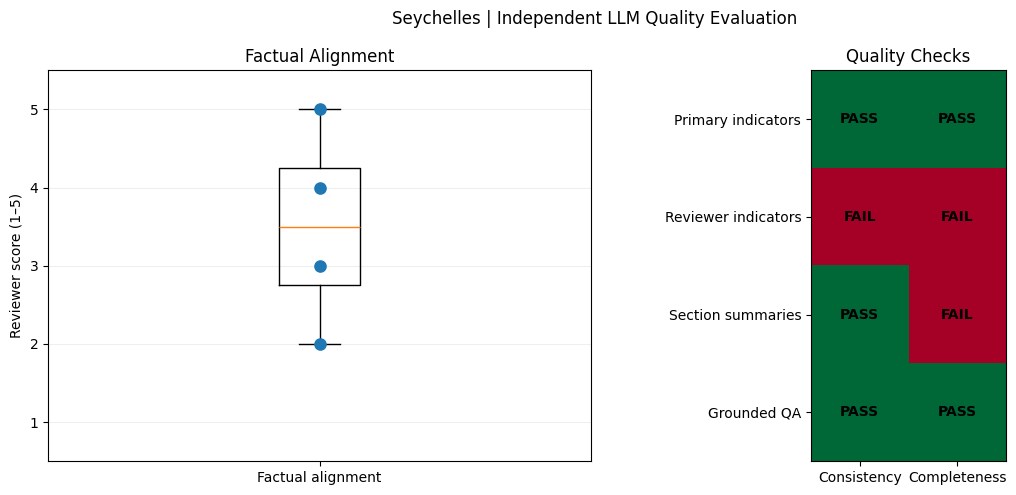

         assessment consistency completeness  factual_alignment
 Primary indicators           3            2                  3
Reviewer indicators       False        False                  2
  Section summaries        True        False                  4
        Grounded QA        True         True                  5


In [37]:
# Figure 4 — Independent LLM Quality Evaluation

reviews = {
    "Primary indicators": audit_mini,
    "Reviewer indicators": audit_second,
    "Section summaries": summary_review,
    "Grounded QA": qa_review
}

audit_df = pd.DataFrame([
    {
        "assessment": name,
        "consistency": result["consistency"],
        "completeness": result["completeness"],
        "factual_alignment": result["factual_alignment"]
    }
    for name, result in reviews.items()
])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# A — Factual alignment scores
scores = audit_df["factual_alignment"].values

axes[0].boxplot(scores, tick_labels=["Factual alignment"])
axes[0].scatter([1] * len(scores), scores, s=65, zorder=3)
axes[0].set_ylim(0.5, 5.5)
axes[0].set_ylabel("Reviewer score (1–5)")
axes[0].set_title("Factual Alignment")
axes[0].grid(axis="y", alpha=0.2)

# B — Boolean assessment results
checks = audit_df[["consistency", "completeness"]].astype(int)

axes[1].imshow(checks.values, cmap="RdYlGn", vmin=0, vmax=1)
axes[1].set_xticks([0, 1], ["Consistency", "Completeness"])
axes[1].set_yticks(range(len(audit_df)), audit_df["assessment"])
axes[1].set_title("Quality Checks")

for i in range(len(audit_df)):
    for j in range(2):
        axes[1].text(
            j, i,
            "PASS" if checks.iloc[i, j] else "FAIL",
            ha="center", va="center",
            fontweight="bold", color="black"
        )

fig.suptitle("Seychelles | Independent LLM Quality Evaluation")
fig.tight_layout()

fig.savefig(
    FIG_OUT / "04_audit_score_boxplot.png",
    dpi=320,
    bbox_inches="tight"
)

plt.show()

audit_df.to_csv(
    AI_OUT / "quality_review_scores.csv",
    index=False
)

print(audit_df.to_string(index=False))

In [38]:
quality_check = {
    "country":"Seychelles",
    "source_report":"IMF Country Report No. 23/402",
    "pdf_pages":len(page_texts),
    "token_windows":len(segments),
    "semantic_vectors":search_index.ntotal,
    "finished_summary_groups":len(synopses),
    "theme_count":len(topic_tallies),
    "strength_count":len(balance_sheet.get("strengths",[])),
    "vulnerability_count":len(balance_sheet.get("vulnerabilities",[])),
    "indicator_keys":list(record_mini),
    "graph_exports":sorted(p.name for p in FIG_OUT.glob("*.png")),
    "known_limitations":[
        "Program review; not Article IV Consultation",
        "Some IMF tables may not extract reliably with pypdf",
        "Short token windows can occur at PDF page ends",
        "Review scores are model judgments, not human gold-standard validation",
        "Missing numeric indicators are stored as -1.0"
    ]
}
put_json(AI_OUT / "run_manifest.json",quality_check)
print(json.dumps(quality_check,indent=2))
assert len(quality_check["graph_exports"]) >= 4, "Expected four saved figures."

{
  "country": "Seychelles",
  "source_report": "IMF Country Report No. 23/402",
  "pdf_pages": 80,
  "token_windows": 130,
  "semantic_vectors": 130,
  "finished_summary_groups": 20,
  "theme_count": 7,
  "strength_count": 5,
  "vulnerability_count": 5,
  "indicator_keys": [
    "country_name",
    "gdp_growth_forecast_pct",
    "headline_inflation_rate_pct",
    "central_bank_policy_rate_pct",
    "non_performing_loan_ratio",
    "unemployment_rate_pct",
    "tier_1_capital_ratio"
  ],
  "graph_exports": [
    "01_risk_theme_mentions.png",
    "02_historical_projection_trend.png",
    "03_cross_model_indicators.png",
    "04_audit_score_boxplot.png"
  ],
  "known_limitations": [
    "Program review; not Article IV Consultation",
    "Some IMF tables may not extract reliably with pypdf",
    "Short token windows can occur at PDF page ends",
    "Review scores are model judgments, not human gold-standard validation",
    "Missing numeric indicators are stored as -1.0"
  ]
}
